In [ ]:
#AIM: TO COMPUTE A PROGRAM FOR THE PURPOSE OF ESTABLISHING ORBITS OF PLANETARY BODIES USING NAIF CODES

In [5]:
"""
NAIF ID     NAME
      ________    ____________________
      0           'SOLAR_SYSTEM_BARYCENTER'
      0           'SSB'
      0           'SOLAR SYSTEM BARYCENTER'
      1           'MERCURY_BARYCENTER'
      1           'MERCURY BARYCENTER'
      2           'VENUS_BARYCENTER'
      2           'VENUS BARYCENTER'
      3           'EARTH_BARYCENTER'
      3           'EMB'
      3           'EARTH MOON BARYCENTER'
      3           'EARTH-MOON BARYCENTER'
      3           'EARTH BARYCENTER'
      4           'MARS_BARYCENTER'
      4           'MARS BARYCENTER'
      5           'JUPITER_BARYCENTER'
      5           'JUPITER BARYCENTER'
      6           'SATURN_BARYCENTER'
      6           'SATURN BARYCENTER'
      7           'URANUS_BARYCENTER'
      7           'URANUS BARYCENTER'
      8           'NEPTUNE_BARYCENTER'
      8           'NEPTUNE BARYCENTER'
      9           'PLUTO_BARYCENTER'
      9           'PLUTO BARYCENTER'
      10          'SUN
"""

"\nNAIF ID     NAME\n      ________    ____________________\n      0           'SOLAR_SYSTEM_BARYCENTER'\n      0           'SSB'\n      0           'SOLAR SYSTEM BARYCENTER'\n      1           'MERCURY_BARYCENTER'\n      1           'MERCURY BARYCENTER'\n      2           'VENUS_BARYCENTER'\n      2           'VENUS BARYCENTER'\n      3           'EARTH_BARYCENTER'\n      3           'EMB'\n      3           'EARTH MOON BARYCENTER'\n      3           'EARTH-MOON BARYCENTER'\n      3           'EARTH BARYCENTER'\n      4           'MARS_BARYCENTER'\n      4           'MARS BARYCENTER'\n      5           'JUPITER_BARYCENTER'\n      5           'JUPITER BARYCENTER'\n      6           'SATURN_BARYCENTER'\n      6           'SATURN BARYCENTER'\n      7           'URANUS_BARYCENTER'\n      7           'URANUS BARYCENTER'\n      8           'NEPTUNE_BARYCENTER'\n      8           'NEPTUNE BARYCENTER'\n      9           'PLUTO_BARYCENTER'\n      9           'PLUTO BARYCENTER'\n      10       

In [2]:
import spiceypy
import numpy as np
import datetime
import matplotlib
import pandas

In [3]:
spiceypy.furnsh('../Kernels/spk/de432s.bsp')
spiceypy.furnsh('../Kernels/lsk/naif0012.tls.txt')
spiceypy.furnsh('../Kernels/pck/pck00010.tpc')


In [4]:
init_time = datetime.datetime(year = 1951, month=1, day=1, hour=00, minute=00, second=00)

delta_days = 10000

end_time = init_time + datetime.timedelta(delta_days)

init_time_str = init_time.strftime("%Y-%M-%dT%H:%M:%S")
end_time_str = end_time.strftime("%Y-%M-%dT%H:%M:%S")

In [5]:
init_time_et = spiceypy.utc2et(init_time_str)
end_time_et = spiceypy.utc2et(end_time_str)

In [6]:
time_interval_et = np.linspace(init_time_et, end_time_et, delta_days)
mars_orbit_array = []
earth_orbit_array = []
pluto_orbit_array = []

for time_instnce in time_interval_et:
    mars_position, _ = spiceypy.spkgps(targ=4, et=time_instnce, ref="ECLIPJ2000", obs=10)
    mars_orbit_array.append(mars_position)

    earth_position, _ = spiceypy.spkgps(targ=3, et=time_instnce, ref="ECLIPJ2000", obs=10)
    earth_orbit_array.append(earth_position)

    pluto_position, _ = spiceypy.spkgps(targ=9, et=time_instnce, ref="ECLIPJ2000", obs=10)
    pluto_orbit_array.append(pluto_position)


    

mars_orbit_array = np.array(mars_orbit_array)
earth_orbit_array = np.array(earth_orbit_array)
pluto_orbit_array = np.array(pluto_orbit_array)

print(mars_orbit_array)


[[ 1.51991021e+08 -1.41242469e+08 -6.70836121e+06]
 [ 1.53470166e+08 -1.39542828e+08 -6.70929565e+06]
 [ 1.54932705e+08 -1.37828087e+08 -6.70950407e+06]
 ...
 [-6.35736796e+07  2.31540128e+08  6.41375570e+06]
 [-6.54873161e+07  2.31159788e+08  6.45291467e+06]
 [-6.73963898e+07  2.30763345e+08  6.49162400e+06]]


In [11]:
_, radii_sun = spiceypy.bodvcd(bodyid=10, item="RADII", maxn=3)

mars_orbit_array_norm = mars_orbit_array/radii_sun
earth_orbit_array_norm = earth_orbit_array/radii_sun
pluto_orbit_array_norm = pluto_orbit_array/radii_sun

print(earth_orbit_array_norm)

[[7.62546809e+01 1.97749221e+02 2.28878364e-02]
 [7.27746452e+01 1.99020356e+02 2.29998264e-02]
 [6.92726693e+01 2.00231490e+02 2.31048913e-02]
 ...
 [1.74363770e+01 2.10794146e+02 1.03802744e-02]
 [1.37329660e+01 2.11049831e+02 1.03738234e-02]
 [1.00253905e+01 2.11241516e+02 1.03642149e-02]]


[[ 530991.84478194 1377006.92303379]
 [ 506758.96408437 1385858.34412257]
 [ 482373.30539287 1394291.95749759]
 ...
 [ 121416.46781361 1467843.95871985]
 [  95628.13541116 1469624.39066336]
 [  69810.8040291  1470959.17448591]]


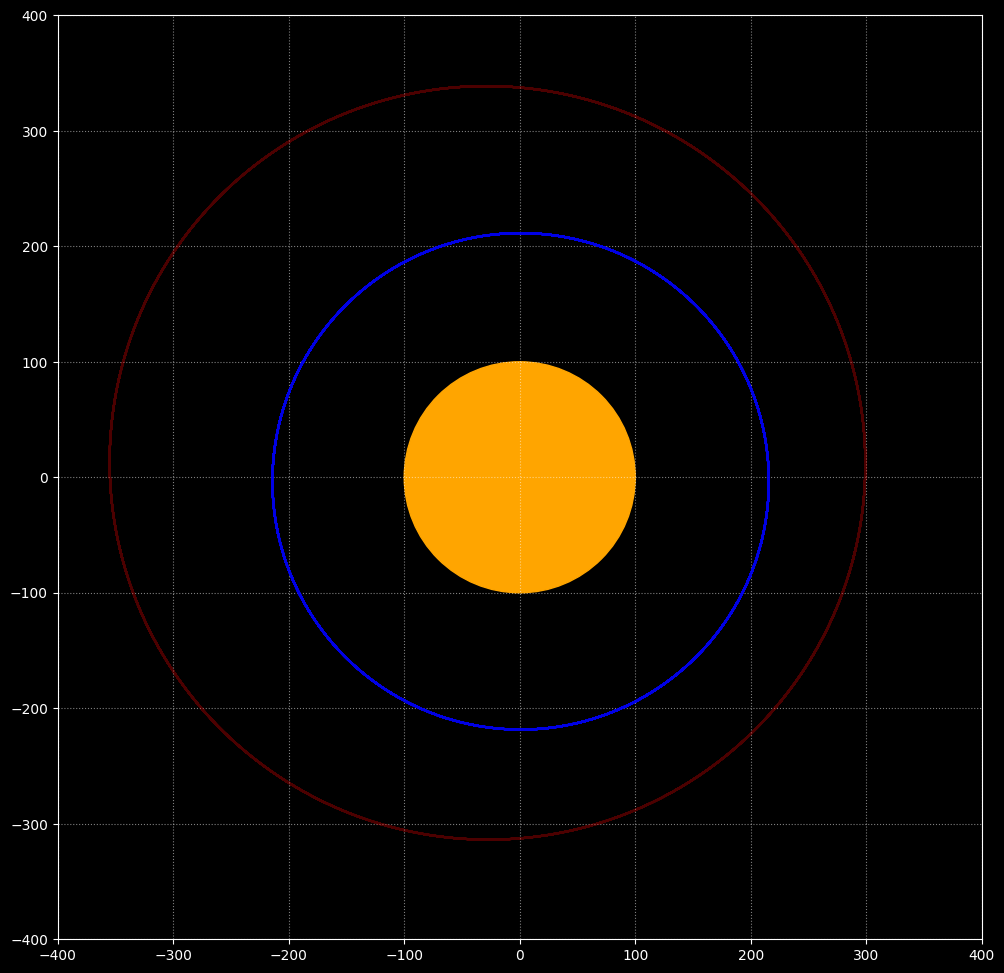

In [16]:
from matplotlib import pyplot as pyplt

mars_orbit_array_xy = mars_orbit_array_norm[:, 0:2]
earth_orbit_array_xy = earth_orbit_array_norm[:, 0:2]
pluto_orbit_array_xy = pluto_orbit_array_norm[:, 0:2]

fig, ax = pyplt.subplots(figsize=(12,12))
pyplt.style.use("dark_background")

ax.set_xlim(-400,400)
ax.set_ylim(-400,400)
ax.set_aspect("equal")
ax.grid(True, linestyle = "dotted", alpha = 0.5)

fig_sun = pyplt.Circle(xy=[0.0, 0.0], radius=100, color="Orange", alpha = 1.0)
ax.add_artist(fig_sun)

pyplt.plot(mars_orbit_array_xy[:, 0], mars_orbit_array_xy[:, 1], ls = "solid", color = "Red", alpha = 0.3)
pyplt.plot(earth_orbit_array_xy[:, 0], earth_orbit_array_xy[:, 1], ls = "solid", color = "blue", alpha = 0.9)
pyplt.plot(pluto_orbit_array_xy[:, 0], pluto_orbit_array_xy[:, 1], ls = "solid", color = "grey", alpha = 0.9)

#print(earth_orbit_array_xy)
array_norm = []

for ele in earth_orbit_array_xy:
    val = 6963.4
    x_cor = ele[0] * val
    y_cor = ele[1] * val
    array_norm.append([x_cor, y_cor])

print(np.array(array_norm))


